# Restaurant Tipping Behavior Analysis (Tips Dataset)
**Role:** Data analyst for a restaurant chain  
**Goals:** (1) train staff to maximise tips, (2) find best-tipping customer segments, (3) decide on automatic gratuity for large parties.

## 1. Setup & Load Data

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os
import numpy as np, pandas as pd
import seaborn as sns, matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

sns.set_theme(style='whitegrid', palette='deep')
os.makedirs('../figures', exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(f'../figures/{name}.png', dpi=150); plt.show()

tips = sns.load_dataset('tips')
tips.to_csv('../data/tips.csv', index=False)
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## 2. Data Cleaning & Quality Checks

In [2]:
print('Shape:', tips.shape)
print('\nMissing values:\n', tips.isna().sum())
print('\nDuplicate rows:', tips.duplicated().sum())
print('\nDtypes:\n', tips.dtypes)
tips.describe()

Shape: (244, 7)

Missing values:
 total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Duplicate rows: 1

Dtypes:
 total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


Only 1 exact duplicate row exists. With no ID column, two parties can plausibly have identical bill/tip/size, so we **keep it** (documented decision). Sanity checks for impossible values:

In [3]:
print('Bills <= 0:', (tips.total_bill<=0).sum(), '| Tips <= 0:', (tips.tip<=0).sum(), '| Size < 1:', (tips['size']<1).sum())
tips['day'] = pd.Categorical(tips['day'], ['Thur','Fri','Sat','Sun'], ordered=True)

Bills <= 0: 0 | Tips <= 0: 0 | Size < 1: 0


## 3. Feature Engineering

In [4]:
df = tips.copy()
df['tip_pct'] = df['tip'] / df['total_bill'] * 100
df['bill_per_person'] = df['total_bill'] / df['size']
df['tip_per_person'] = df['tip'] / df['size']
df['is_weekend'] = df['day'].isin(['Sat','Sun'])
df['party_group'] = pd.cut(df['size'], [0,2,4,10], labels=['Small (1-2)','Medium (3-4)','Large (5+)'])
df['bill_bracket'] = pd.qcut(df['total_bill'], 4, labels=['Q1 low','Q2','Q3','Q4 high'])
df['tip_class'] = pd.cut(df['tip_pct'], [0,10,15,20,100], labels=['<10% (poor)','10-15%','15-20% (standard)','>20% (generous)'])
df[['total_bill','tip','tip_pct','bill_per_person','party_group','tip_class']].head()

,total_bill,tip,tip_pct,bill_per_person,party_group,tip_class
0,16.99,1.01,5.944673,8.495000,Small (1-2),<10% (poor)
1,10.34,1.66,16.054159,3.446667,Medium (3-4),15-20% (standard)
2,21.01,3.50,16.658734,7.003333,Medium (3-4),15-20% (standard)
3,23.68,3.31,13.978041,11.840000,Small (1-2),10-15%
4,24.59,3.61,14.680765,6.147500,Medium (3-4),10-15%


## 4. Univariate EDA

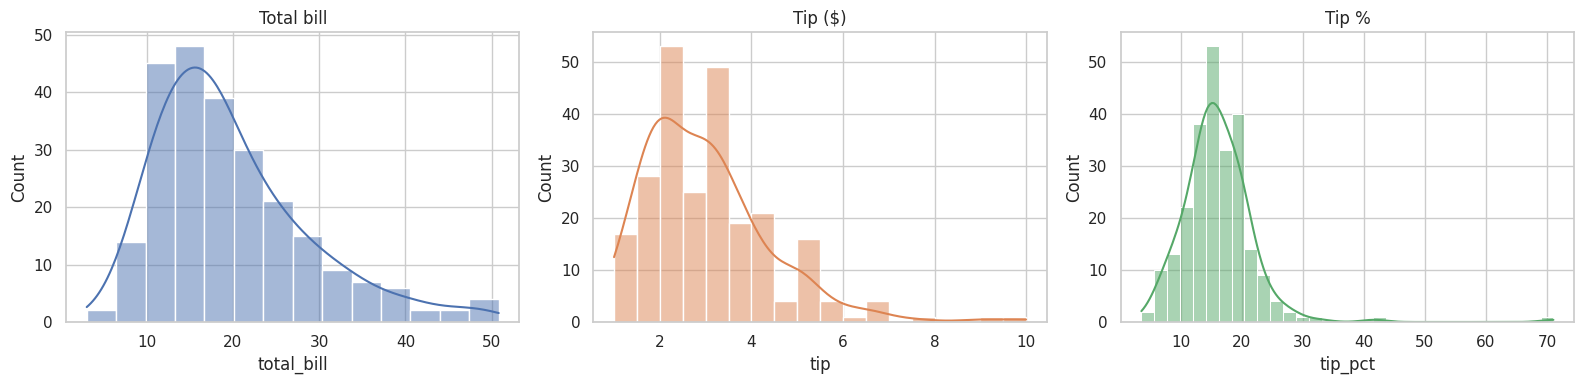

Skew -> bill: 1.13, tip: 1.47, tip%: 3.35


In [5]:
fig, ax = plt.subplots(1,3, figsize=(16,4))
sns.histplot(df.total_bill, kde=True, ax=ax[0]); ax[0].set_title('Total bill')
sns.histplot(df.tip, kde=True, ax=ax[1], color='C1'); ax[1].set_title('Tip ($)')
sns.histplot(df.tip_pct, kde=True, ax=ax[2], color='C2'); ax[2].set_title('Tip %')
save('01_distributions')
print('Skew -> bill: %.2f, tip: %.2f, tip%%: %.2f' % (df.total_bill.skew(), df.tip.skew(), df.tip_pct.skew()))

## 5. Business Questions

### Q1. Average tip percentage – is it in the 15–20% band?

Mean tip%: 16.08 | Median: 15.48 | Std: 6.11
Overall (sum tip / sum bill): 15.15%
tip_class
<10% (poor)          11.1
10-15%               33.6
15-20% (standard)    39.3
>20% (generous)      16.0
Name: proportion, dtype: float64
One-sample t-test vs 15%: t=2.76, p=0.0062
95% CI for mean tip%: [15.31 16.85]


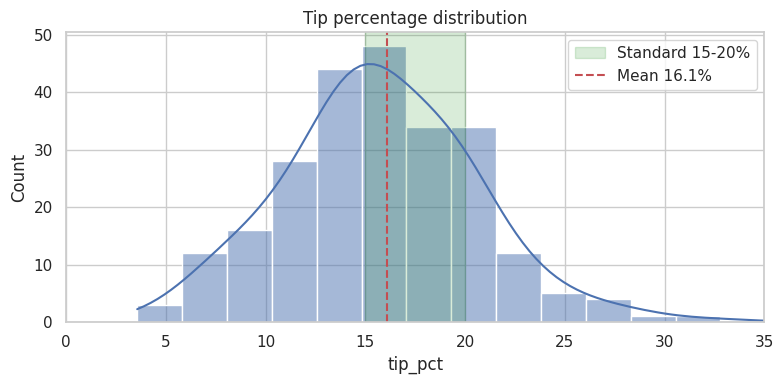

In [6]:
m, med = df.tip_pct.mean(), df.tip_pct.median()
print(f'Mean tip%: {m:.2f} | Median: {med:.2f} | Std: {df.tip_pct.std():.2f}')
print(f'Overall (sum tip / sum bill): {df.tip.sum()/df.total_bill.sum()*100:.2f}%')
print(df.tip_class.value_counts(normalize=True).sort_index().mul(100).round(1))
t,p = stats.ttest_1samp(df.tip_pct, 15)
print(f'One-sample t-test vs 15%: t={t:.2f}, p={p:.2g}')
ci = stats.t.interval(0.95, len(df)-1, m, stats.sem(df.tip_pct)); print('95% CI for mean tip%:', np.round(ci,2))
plt.figure(figsize=(8,4)); sns.histplot(df.tip_pct, bins=30, kde=True)
plt.axvspan(15,20,color='green',alpha=.15,label='Standard 15-20%'); plt.axvline(m,color='r',ls='--',label=f'Mean {m:.1f}%')
plt.xlim(0,35); plt.legend(); plt.title('Tip percentage distribution'); save('02_tip_pct_distribution')

### Q2. Men vs women

          n  avg_bill  avg_tip  avg_tip_pct  median_tip_pct
sex                                                        
Male    157     20.74     3.09        15.77           15.35
Female   87     18.06     2.83        16.65           15.56
tip: Welch t p=0.138 | Mann-Whitney p=0.383
tip_pct: Welch t p=0.254 | Mann-Whitney p=0.135
total_bill: Welch t p=0.019 | Mann-Whitney p=0.021


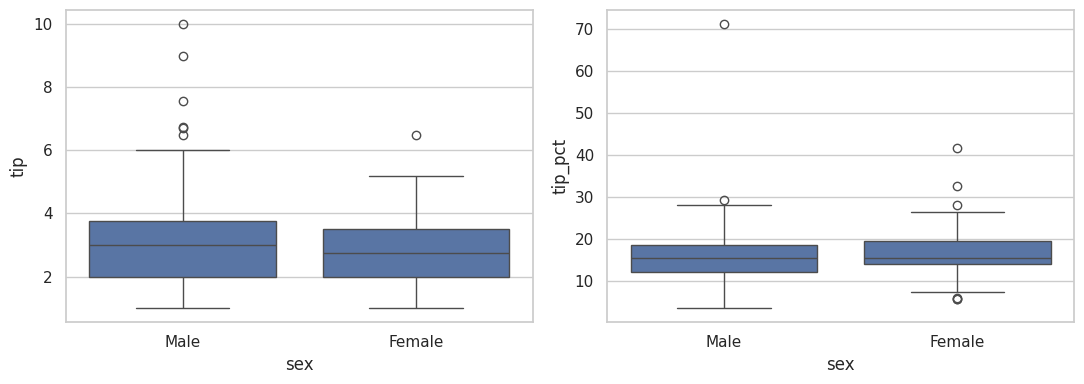

In [7]:
g = df.groupby('sex').agg(n=('tip','size'), avg_bill=('total_bill','mean'), avg_tip=('tip','mean'), avg_tip_pct=('tip_pct','mean'), median_tip_pct=('tip_pct','median')).round(2)
print(g)
def compare(col, a, b, by):
    x, y = df[df[by]==a][col], df[df[by]==b][col]
    t,p = stats.ttest_ind(x,y,equal_var=False); u,pu = stats.mannwhitneyu(x,y)
    print(f'{col}: Welch t p={p:.3f} | Mann-Whitney p={pu:.3f}')
compare('tip','Male','Female','sex'); compare('tip_pct','Male','Female','sex'); compare('total_bill','Male','Female','sex')
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.boxplot(data=df,x='sex',y='tip',ax=ax[0]); sns.boxplot(data=df,x='sex',y='tip_pct',ax=ax[1]); save('03_sex')

### Q3. Smokers vs non-smokers

          n  avg_bill  avg_tip  avg_tip_pct  median_tip_pct
smoker                                                     
Yes      93     20.76     3.01        16.32           15.38
No      151     19.19     2.99        15.93           15.56
tip: Welch t p=0.927 | Mann-Whitney p=0.792
tip_pct: Welch t p=0.682 | Mann-Whitney p=0.561


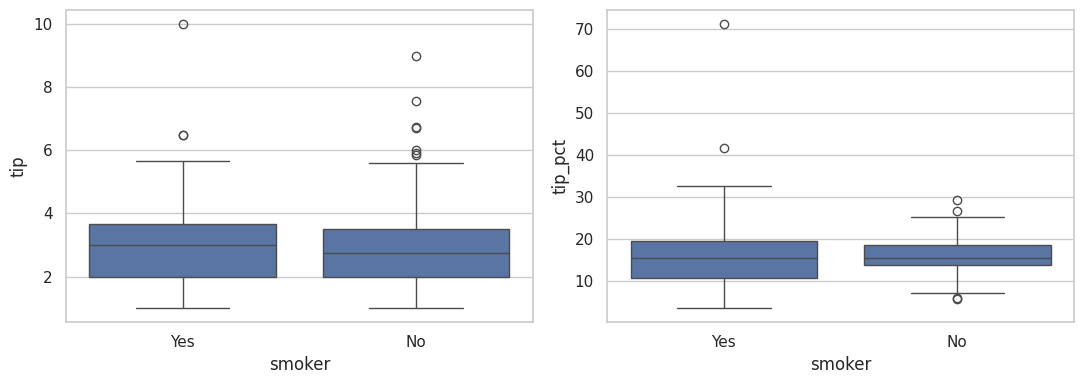

In [8]:
print(df.groupby('smoker').agg(n=('tip','size'), avg_bill=('total_bill','mean'), avg_tip=('tip','mean'), avg_tip_pct=('tip_pct','mean'), median_tip_pct=('tip_pct','median')).round(2))
compare('tip','Yes','No','smoker'); compare('tip_pct','Yes','No','smoker')
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.boxplot(data=df,x='smoker',y='tip',ax=ax[0]); sns.boxplot(data=df,x='smoker',y='tip_pct',ax=ax[1]); save('04_smoker')

### Q4. Which day produces the highest tips?

      parties  total_tips  avg_tip  avg_tip_pct  avg_size  avg_bill
day                                                                
Thur       62      171.83     2.77        16.13      2.45     17.68
Fri        19       51.96     2.73        16.99      2.11     17.15
Sat        87      260.40     2.99        15.32      2.52     20.44
Sun        76      247.39     3.26        16.69      2.84     21.41
ANOVA tip$: F_onewayResult(statistic=np.float64(1.6723551980998697), pvalue=np.float64(0.1735885553040583))
ANOVA tip%: F_onewayResult(statistic=np.float64(0.848004878913012), pvalue=np.float64(0.4688408992352633))
Kruskal tip%: KruskalResult(statistic=np.float64(1.83705662552094), pvalue=np.float64(0.6069043899742481))


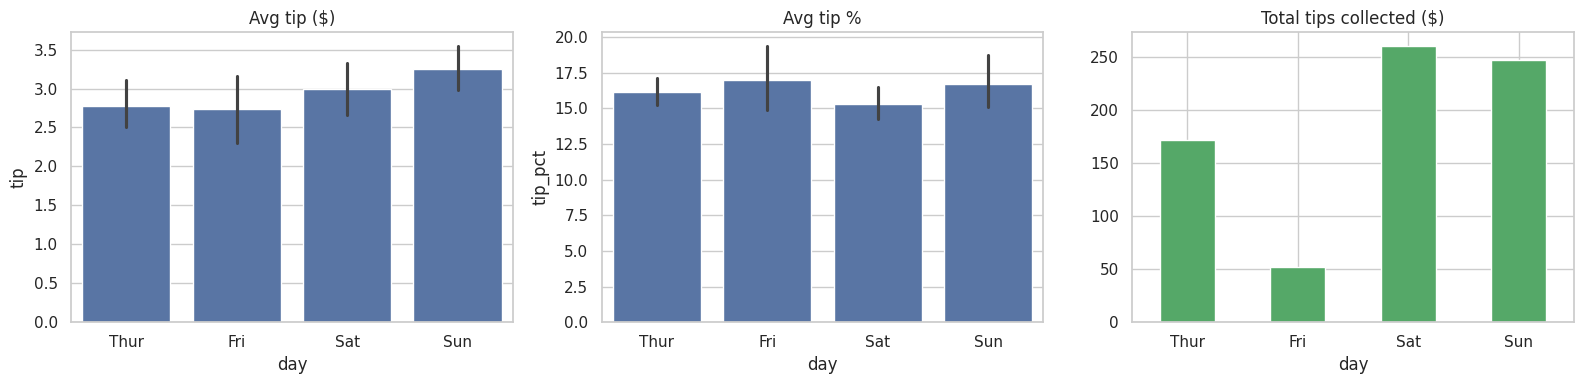

In [9]:
d = df.groupby('day', observed=True).agg(parties=('tip','size'), total_tips=('tip','sum'), avg_tip=('tip','mean'), avg_tip_pct=('tip_pct','mean'), avg_size=('size','mean'), avg_bill=('total_bill','mean')).round(2)
print(d)
print('ANOVA tip$:', stats.f_oneway(*[g.tip for _,g in df.groupby('day',observed=True)]))
print('ANOVA tip%:', stats.f_oneway(*[g.tip_pct for _,g in df.groupby('day',observed=True)]))
print('Kruskal tip%:', stats.kruskal(*[g.tip_pct for _,g in df.groupby('day',observed=True)]))
fig,ax=plt.subplots(1,3,figsize=(16,4))
sns.barplot(data=df,x='day',y='tip',ax=ax[0],errorbar='ci'); ax[0].set_title('Avg tip ($)')
sns.barplot(data=df,x='day',y='tip_pct',ax=ax[1],errorbar='ci'); ax[1].set_title('Avg tip %')
d.total_tips.plot(kind='bar',ax=ax[2],color='C2',rot=0); ax[2].set_title('Total tips collected ($)'); save('05_day')

### Q5. Dinner vs lunch

        parties  total_tips  avg_bill  avg_tip  avg_tip_pct  avg_size
time                                                                 
Lunch        68      185.51     17.17     2.73        16.41      2.41
Dinner      176      546.07     20.80     3.10        15.95      2.63
tip: Welch t p=0.041 | Mann-Whitney p=0.029
tip_pct: Welch t p=0.514 | Mann-Whitney p=0.230
time  Lunch  Dinner
day                
Thur     61       1
Fri       7      12
Sat       0      87
Sun       0      76


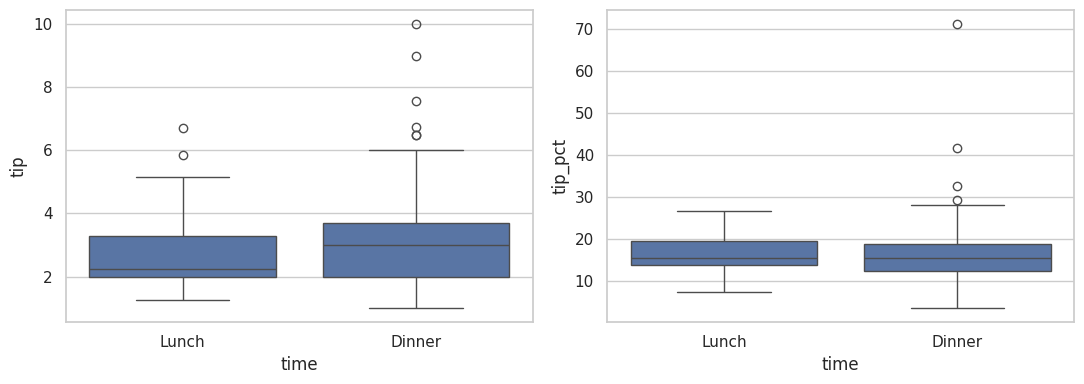

In [10]:
print(df.groupby('time').agg(parties=('tip','size'), total_tips=('tip','sum'), avg_bill=('total_bill','mean'), avg_tip=('tip','mean'), avg_tip_pct=('tip_pct','mean'), avg_size=('size','mean')).round(2))
compare('tip','Dinner','Lunch','time'); compare('tip_pct','Dinner','Lunch','time')
print(pd.crosstab(df.day, df.time))
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.boxplot(data=df,x='time',y='tip',ax=ax[0]); sns.boxplot(data=df,x='time',y='tip_pct',ax=ax[1]); save('06_time')

### Q6. Party size and tip % (the 'big-group myth')

      parties  avg_tip  avg_tip_pct  median_tip_pct  avg_tip_per_person
size                                                                   
1           4     1.44        21.73           20.28                1.44
2         156     2.58        16.57           15.61                1.29
3          38     3.39        15.22           15.93                1.13
4          37     4.14        14.59           14.67                1.03
5           5     4.03        14.15           12.14                0.81
6           4     5.22        15.62           16.29                0.87
              parties  avg_tip  avg_tip_pct
party_group                                
Small (1-2)       160     2.55        16.70
Medium (3-4)       75     3.76        14.91
Large (5+)          9     4.56        14.80
Spearman size vs tip%: rho=-0.152, p=0.017
Pearson size vs tip$: r=0.489, p=4.3e-16
Kruskal tip% across groups: KruskalResult(statistic=np.float64(4.082516134023835), pvalue=np.float64(0.1298652289038696)

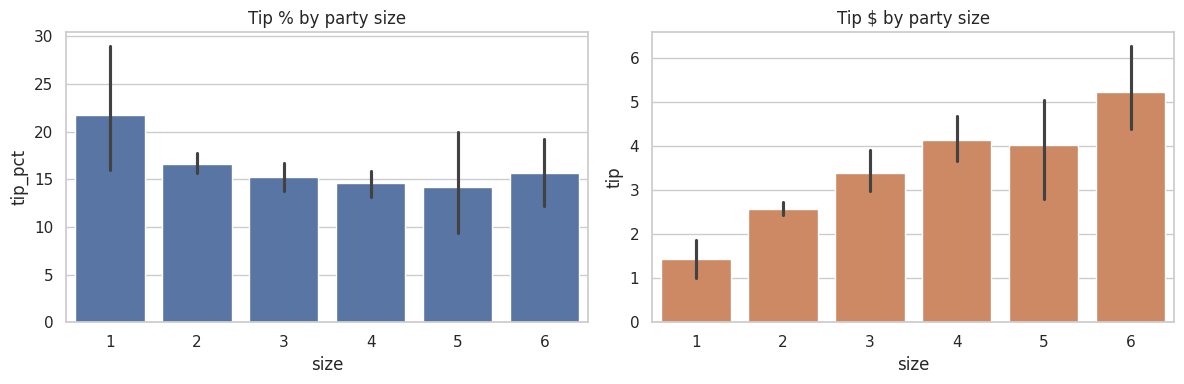

In [11]:
s = df.groupby('size').agg(parties=('tip','size'), avg_tip=('tip','mean'), avg_tip_pct=('tip_pct','mean'), median_tip_pct=('tip_pct','median'), avg_tip_per_person=('tip_per_person','mean')).round(2)
print(s)
print(df.groupby('party_group', observed=True).agg(parties=('tip','size'), avg_tip=('tip','mean'), avg_tip_pct=('tip_pct','mean')).round(2))
r,p = stats.spearmanr(df['size'], df.tip_pct); print(f'Spearman size vs tip%: rho={r:.3f}, p={p:.3f}')
r2,p2 = stats.pearsonr(df['size'], df.tip); print(f'Pearson size vs tip$: r={r2:.3f}, p={p2:.2g}')
print('Kruskal tip% across groups:', stats.kruskal(*[g.tip_pct for _,g in df.groupby('party_group',observed=True)]))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.barplot(data=df,x='size',y='tip_pct',ax=ax[0]); ax[0].set_title('Tip % by party size')
sns.barplot(data=df,x='size',y='tip',ax=ax[1],color='C1'); ax[1].set_title('Tip $ by party size'); save('07_party_size')

Large parties (5+) are rare in this data, so conclusions about them carry **low statistical power**.

### Q7. Outliers (very low / very high tippers)

Tip% IQR fences: 3.6 - 28.5

Tip% outliers (IQR): 4
     total_bill   tip  tip_pct     sex smoker  day    time  size
232       11.61  3.39    29.20    Male     No  Sat  Dinner     2
67         3.07  1.00    32.57  Female    Yes  Sat  Dinner     1
178        9.60  4.00    41.67  Female    Yes  Sun  Dinner     2
172        7.25  5.15    71.03    Male    Yes  Sun  Dinner     2

Tip $ fences: -0.34 - 5.91
Tip $ outliers: 9
     total_bill    tip  tip_pct   day    time  size
23        39.42   7.58    19.23   Sat  Dinner     4
47        32.40   6.00    18.52   Sun  Dinner     4
59        48.27   6.73    13.94   Sat  Dinner     4
141       34.30   6.70    19.53  Thur   Lunch     6
170       50.81  10.00    19.68   Sat  Dinner     3
183       23.17   6.50    28.05   Sun  Dinner     4
212       48.33   9.00    18.62   Sat  Dinner     4
214       28.17   6.50    23.07   Sat  Dinner     3
239       29.03   5.92    20.39   Sat  Dinner     3

Parties tipping <10%: 27 (11.1%)  |  >25%: 10


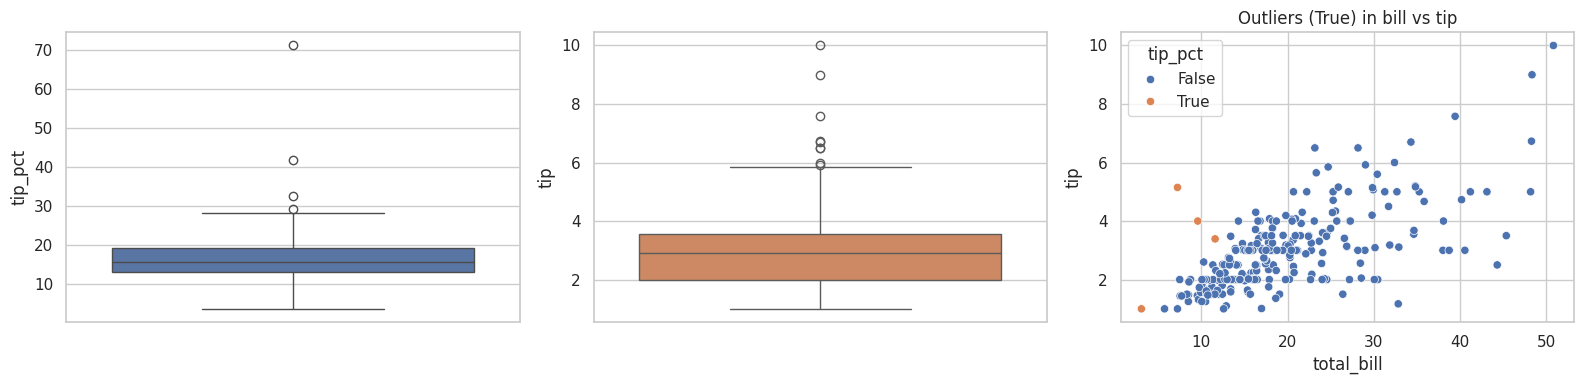

In [12]:
def iqr_bounds(s):
    q1,q3=s.quantile([.25,.75]); i=q3-q1; return q1-1.5*i, q3+1.5*i
lo,hi = iqr_bounds(df.tip_pct); print(f'Tip% IQR fences: {lo:.1f} - {hi:.1f}')
df['z_tip_pct'] = stats.zscore(df.tip_pct)
out_pct = df[(df.tip_pct<lo)|(df.tip_pct>hi)]
print('\nTip% outliers (IQR):', len(out_pct)); print(out_pct.sort_values('tip_pct')[['total_bill','tip','tip_pct','sex','smoker','day','time','size']].round(2))
lo2,hi2 = iqr_bounds(df.tip); print(f'\nTip $ fences: {lo2:.2f} - {hi2:.2f}')
print('Tip $ outliers:', ((df.tip>hi2)|(df.tip<lo2)).sum())
print(df[df.tip>hi2][['total_bill','tip','tip_pct','day','time','size']].round(2))
print('\nParties tipping <10%:', (df.tip_pct<10).sum(), f'({(df.tip_pct<10).mean()*100:.1f}%)  |  >25%:', (df.tip_pct>25).sum())
fig,ax=plt.subplots(1,3,figsize=(16,4))
sns.boxplot(y=df.tip_pct,ax=ax[0]); sns.boxplot(y=df.tip,ax=ax[1],color='C1')
sns.scatterplot(data=df,x='total_bill',y='tip',hue=(df.tip_pct<lo)|(df.tip_pct>hi),ax=ax[2]); ax[2].set_title('Outliers (True) in bill vs tip'); save('08_outliers')

### Q8. Which combination of features predicts the highest tips?

                 total_bill   tip  size  tip_pct  bill_per_person
total_bill             1.00  0.68  0.60    -0.34             0.65
tip                    0.68  1.00  0.49     0.34             0.35
size                   0.60  0.49  1.00    -0.14            -0.18
tip_pct               -0.34  0.34 -0.14     1.00            -0.31
bill_per_person        0.65  0.35 -0.18    -0.31             1.00


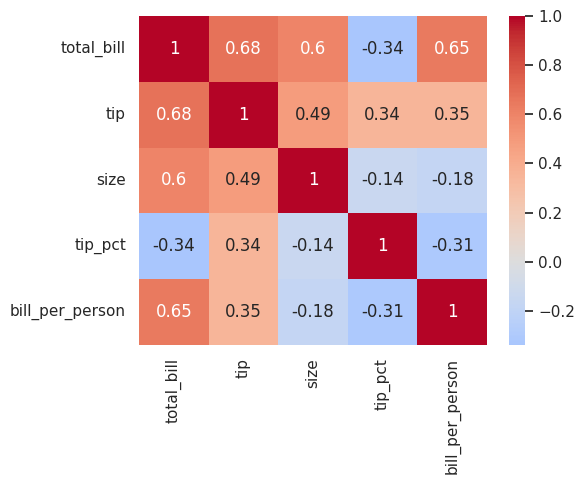


Top segments by average tip $ (n>=8):
                     n  avg_tip  avg_tip_pct
day  time   smoker                          
Sun  Dinner Yes     19     3.52        18.73
            No      57     3.17        16.01
Sat  Dinner No      45     3.10        15.80
Thur Lunch  Yes     17     3.03        16.39
Fri  Dinner Yes      9     3.00        16.53

Top segments by average tip % (n>=8):
                     n  avg_tip  avg_tip_pct
day  time   smoker                          
Sun  Dinner Yes     19     3.52        18.73
Fri  Dinner Yes      9     3.00        16.53
Thur Lunch  Yes     17     3.03        16.39
            No      44     2.67        16.03
Sun  Dinner No      57     3.17        16.01


In [13]:
print(df[['total_bill','tip','size','tip_pct','bill_per_person']].corr().round(2))
plt.figure(figsize=(6,5)); sns.heatmap(df[['total_bill','tip','size','tip_pct','bill_per_person']].corr(),annot=True,cmap='coolwarm',center=0); save('09_corr')
combo = df.groupby(['day','time','smoker'], observed=True).agg(n=('tip','size'), avg_tip=('tip','mean'), avg_tip_pct=('tip_pct','mean')).round(2)
print('\nTop segments by average tip $ (n>=8):'); print(combo[combo.n>=8].sort_values('avg_tip',ascending=False).head(5))
print('\nTop segments by average tip % (n>=8):'); print(combo[combo.n>=8].sort_values('avg_tip_pct',ascending=False).head(5))

Linear: test R2=0.350, MAE=$0.70, CV R2=0.421


RandomForest: test R2=0.346, MAE=$0.71, CV R2=0.403


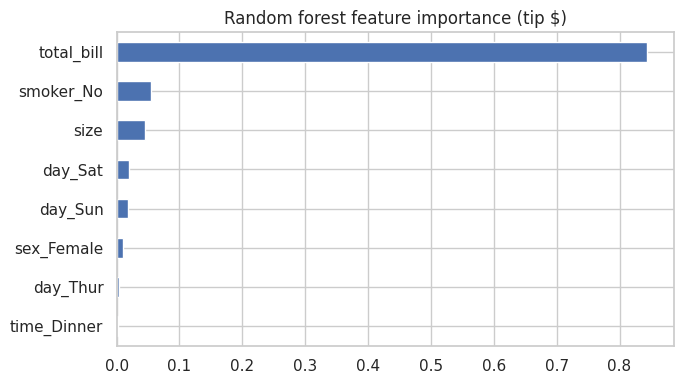

total_bill     0.844
smoker_No      0.055
size           0.045
day_Sat        0.020
day_Sun        0.018
sex_Female     0.010
day_Thur       0.005
time_Dinner    0.003
dtype: float64


In [14]:
# Predictive modelling: which features matter for tip $
X = pd.get_dummies(df[['total_bill','size','sex','smoker','day','time']].astype({'day':str}), drop_first=True)
y = df.tip
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=.25,random_state=42)
lr = LinearRegression().fit(Xtr,ytr); rf = RandomForestRegressor(n_estimators=300,min_samples_leaf=5,random_state=42).fit(Xtr,ytr)
for n,m in [('Linear',lr),('RandomForest',rf)]:
    print(f'{n}: test R2={r2_score(yte,m.predict(Xte)):.3f}, MAE=${mean_absolute_error(yte,m.predict(Xte)):.2f}, CV R2={cross_val_score(m,X,y,cv=5,scoring="r2").mean():.3f}')
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
imp.plot(kind='barh',figsize=(7,4),title='Random forest feature importance (tip $)'); save('10_feature_importance')
print(imp.sort_values(ascending=False).round(3))

In [15]:
import statsmodels.formula.api as smf
m1 = smf.ols('tip_pct ~ total_bill + C(size) + C(sex) + C(smoker) + C(day) + C(time)', data=df.assign(day=df.day.astype(str))).fit()
print('Predicting tip %% (OLS): R2 = %.3f' % m1.rsquared)
print(m1.summary().tables[1])

Predicting tip % (OLS): R2 = 0.149


                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            24.5390      3.382      7.256      0.000      17.876      31.202
C(size)[T.2]         -2.7111      3.015     -0.899      0.370      -8.652       3.230
C(size)[T.3]         -2.2279      3.203     -0.696      0.487      -8.538       4.082
C(size)[T.4]         -1.4590      3.311     -0.441      0.660      -7.983       5.066
C(size)[T.5]         -1.8292      4.123     -0.444      0.658      -9.952       6.294
C(size)[T.6]          1.9199      4.438      0.433      0.666      -6.824      10.664
C(sex)[T.Female]      0.3662      0.804      0.455      0.649      -1.218       1.951
C(smoker)[T.No]      -1.2915      0.831     -1.554      0.122      -2.929       0.346
C(day)[T.Sat]        -0.3216      1.760     -0.183      0.855      -3.790       3.147
C(day)[T.Sun]         1.5266      1.822      0.838    

## 6. Findings & Recommendations
See the **README.md** for the written summary of the results above.